Import libraries and configure paths

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project directory
PROJECT_ROOT = Path.cwd()

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "paddy_production.csv"
)

print("Project directory:", PROJECT_ROOT)
print("Dataset path:", DATA_PATH)

Project directory: D:\UOM\L4S1\CM4371 - Machine Learning & Pattern Recognition\MLPR_Project
Dataset path: D:\UOM\L4S1\CM4371 - Machine Learning & Pattern Recognition\MLPR_Project\data\raw\paddy_production.csv


Load dataset

In [2]:
df = pd.read_csv(DATA_PATH)

# Remove accidental spaces in column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")

display(df.head())

Dataset loaded successfully!


,Year,Sown 000 Acres,Sown 000 Ha,Harvested 000 Acres,Harvested 000 Ha.,Average Yield Bushels/Acre,Average Yield Kg/Ha,Production 000 Bushels,Production 000 Mt.
0,1952,1162,471,1102,446,30.775,1587.0,28900,604
1,1953,1049,425,952,385,27.170,1401.0,21900,458
2,1954,1253,508,1201,486,30.010,1547.0,31100,650
3,1955,1347,545,1285,520,32.540,1678.0,35700,747
4,1956,1177,476,1052,426,29.540,1523.5,27500,574


Historical production trend

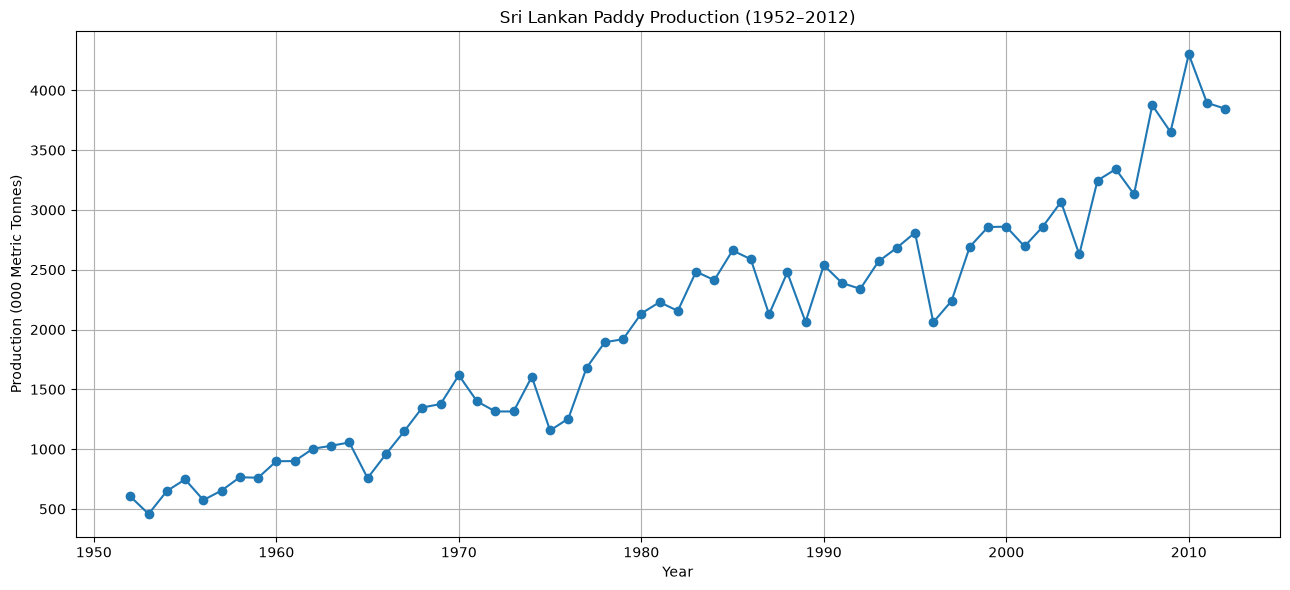

In [3]:
plt.figure(figsize=(13, 6))

plt.plot(
    df["Year"],
    df["Production 000 Mt."],
    marker="o"
)

plt.title("Sri Lankan Paddy Production (1952–2012)")

plt.xlabel("Year")

plt.ylabel("Production (000 Metric Tonnes)")

plt.grid(True)

plt.tight_layout()

plt.show()

Production distribution

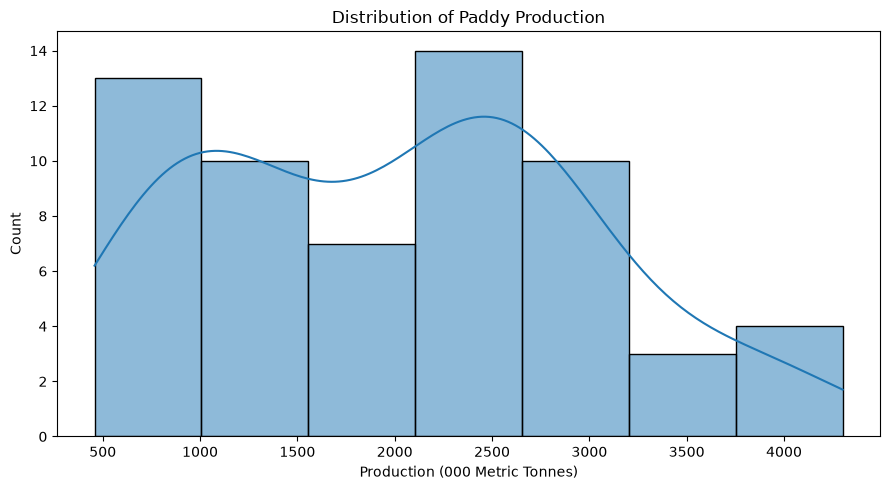

In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["Production 000 Mt."],
    kde=True
)

plt.title("Distribution of Paddy Production")

plt.xlabel("Production (000 Metric Tonnes)")

plt.tight_layout()

plt.show()

Calculate yearly production changes

In [5]:
df["Production Change"] = (
    df["Production 000 Mt."].diff()
)

display(
    df[["Year", "Production 000 Mt.", "Production Change"]].head(10)
)

,Year,Production 000 Mt.,Production Change
0,1952,604,NaN
1,1953,458,-146.0
2,1954,650,192.0
3,1955,747,97.0
4,1956,574,-173.0
5,1957,654,80.0
6,1958,765,111.0
7,1959,761,-4.0
8,1960,899,138.0
9,1961,900,1.0


Yearly production changes visualization

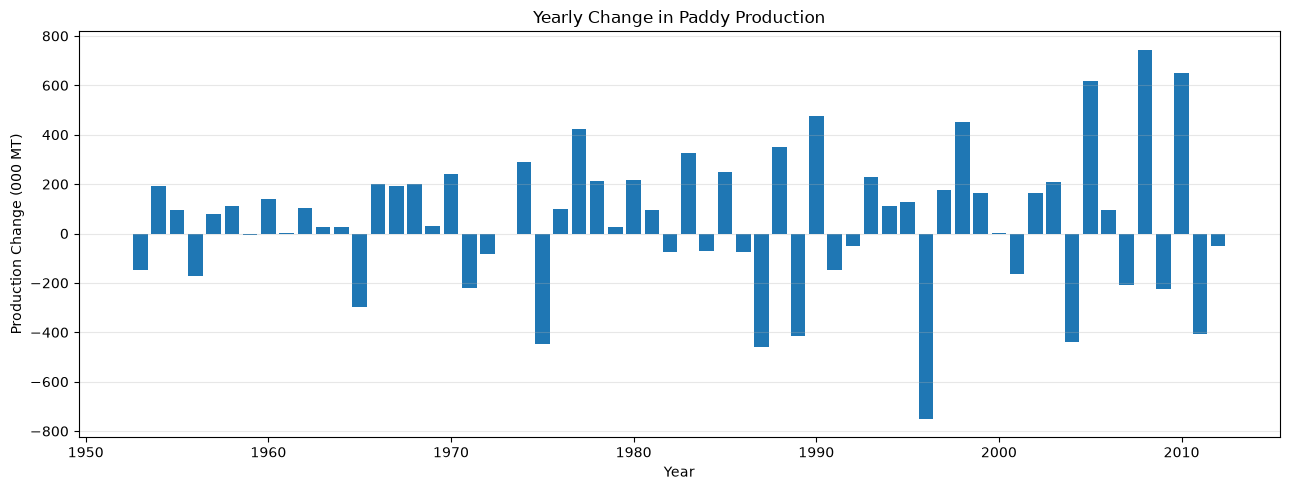

In [6]:
plt.figure(figsize=(13, 5))

plt.bar(
    df["Year"],
    df["Production Change"]
)

plt.title("Yearly Change in Paddy Production")

plt.xlabel("Year")

plt.ylabel("Production Change (000 MT)")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.show()

Visualization summary

In [7]:
print("========== VISUALIZATION SUMMARY ==========")

print(
    "Historical period:",
    df["Year"].min(),
    "-",
    df["Year"].max()
)

print(
    "Average production:",
    round(df["Production 000 Mt."].mean(), 2),
    "000 MT"
)

print(
    "Maximum production:",
    round(df["Production 000 Mt."].max(), 2),
    "000 MT"
)

print(
    "Minimum production:",
    round(df["Production 000 Mt."].min(), 2),
    "000 MT"
)

print(
    "Average yearly production change:",
    round(df["Production Change"].mean(), 2),
    "000 MT"
)

========== VISUALIZATION SUMMARY ==========
Historical period: 1952 - 2012
Average production: 2012.31 000 MT
Maximum production: 4301 000 MT
Minimum production: 458 000 MT
Average yearly production change: 54.03 000 MT
